# Cambridge Housing Affordability: Key Indicators (2024)

Three metrics that together describe the affordability gap:

| Metric | What it measures |
|---|---|
| **Median home price** | Market price of residential properties, by type |
| **Price-to-income ratio (PTI)** | Home price relative to median household income |
| **Net housing units per 1,000 households** | Rate of new supply, 1996–2025 |

## Data

- **Home prices**: arm's-length sales (saleprice ≥ $50k, saledate 2022–2024) from the Cambridge Property Database (FY2026 records, Socrata `eey2-rv59`). Only recently-transacted properties appear — long-held stock is excluded by construction.
- **Home prices (alternative)**: Zillow Home Value Index (ZHVI), SFR+condo, middle tier (33rd–67th percentile), Cambridge city, MA. Covers all homes via AVM, not just recent transactions. Source: Zillow Research, `City_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv`.
- **Household income**: ACS 1-Year Estimates 2024, Table S1901, Cambridge city. Median household income $143,108 (±$12,718). Note: includes MIT/Harvard student non-family households, which depress the citywide median relative to owner-occupying families.
- **Household count**: ACS 2024 S1901 — 51,275 households (±2,110).
- **Housing starts**: Cambridge Open Data Portal (dataset 6nxj-uqfe), manually curated version. 1996–2025; 2025 data is confirmed complete despite a very low count (62 net units).

## Known limitations

- Sale prices cover only transacted properties. The SFH sample (N=329 over three years) is thin and may skew toward more typical or recently developed homes; the rarest/most expensive long-held SFHs almost never transact. The ZHVI addresses this by covering the full stock.
- ACS income is for all households, not just owner-occupants. Actual buyer incomes are higher, which makes the PTI somewhat overstate the burden for current buyers while understating entry barriers for median-income households.


In [1]:
from pathlib import Path
import csv, statistics, datetime, os

DATA_RAW = Path("../data/raw")
DATA_OUT = Path("../data/out")
DATA_OUT.mkdir(parents=True, exist_ok=True)

PROP_CSV  = DATA_RAW / "cambridge_property_assessments.csv"
PERM_CSV  = DATA_RAW / "cambridge_housing_permits_curated.csv"
ACS_CSV   = DATA_RAW / "ACSST1Y2024.S1901-2026-05-19T234744.csv"

assert PROP_CSV.exists(), f"Run scripts/fetch_property_assessments.py first: {PROP_CSV}"
assert PERM_CSV.exists(), f"Missing: {PERM_CSV}"
assert ACS_CSV.exists(),  f"Missing: {ACS_CSV}"

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

SERIF = "DejaVu Serif"


In [2]:
print("=== Data provenance ===")
prop_mtime = datetime.datetime.fromtimestamp(os.path.getmtime(PROP_CSV))
perm_mtime = datetime.datetime.fromtimestamp(os.path.getmtime(PERM_CSV))
print(f"  Property assessments: {PROP_CSV.name}")
print(f"    Last fetched: {prop_mtime.strftime('%Y-%m-%d')}")
print(f"    Source: Cambridge Property Database FY2016–FY2026 (Socrata eey2-rv59)")
print()
print(f"  Housing permits: {PERM_CSV.name}")
print(f"    Last modified: {perm_mtime.strftime('%Y-%m-%d')}")
print()
print(f"  ACS income: {ACS_CSV.name}")
print(f"    Source: U.S. Census Bureau, ACS 1-Year Estimates 2024, Table S1901")
print(f"    Geography: Cambridge city, Middlesex County, Massachusetts")
print(f"    Accessed: 2026-05-19")


=== Data provenance ===
  Property assessments: cambridge_property_assessments.csv
    Last fetched: 2026-05-21
    Source: Cambridge Property Database FY2016–FY2026 (Socrata eey2-rv59)

  Housing permits: cambridge_housing_permits_curated.csv
    Last modified: 2026-05-21

  ACS income: ACSST1Y2024.S1901-2026-05-19T234744.csv
    Source: U.S. Census Bureau, ACS 1-Year Estimates 2024, Table S1901
    Geography: Cambridge city, Middlesex County, Massachusetts
    Accessed: 2026-05-19


## Median household income and household count (ACS 2024)

In [3]:
with open(ACS_CSV, encoding="utf-8-sig") as f:
    acs_rows = {r["Label (Grouping)"].strip(): r for r in csv.DictReader(f)}

# Household column name
HH_COL = "Cambridge city, Middlesex County, Massachusetts!!Households!!Estimate"
HH_MOE = "Cambridge city, Middlesex County, Massachusetts!!Households!!Margin of Error"

def parse_acs(val):
    return float(val.replace(",", "").replace("+/-", "").strip())

TOTAL_HH        = parse_acs(acs_rows["Total"][HH_COL])
TOTAL_HH_MOE    = parse_acs(acs_rows["Total"][HH_MOE].replace("±","").strip())
MEDIAN_HH_INC   = parse_acs(acs_rows["Median income (dollars)"][HH_COL])
MEDIAN_HH_MOE   = parse_acs(acs_rows["Median income (dollars)"][HH_MOE].replace("±","").strip())

print(f"Total households:      {TOTAL_HH:,.0f}  (±{TOTAL_HH_MOE:,.0f})")
print(f"Median HH income:     ${MEDIAN_HH_INC:,.0f}  (±${MEDIAN_HH_MOE:,.0f})")
print()
print("Note: median for family households is $197,674; non-family (incl. students) is $111,685.")
print("This analysis uses the all-household median as the standard affordability benchmark.")


Total households:      51,275  (±2,110)
Median HH income:     $143,108  (±$12,718)

Note: median for family households is $197,674; non-family (incl. students) is $111,685.
This analysis uses the all-household median as the standard affordability benchmark.


## Inflation adjustment (CPI-U, 2024 dollars)

All dollar figures in this notebook are expressed in **2024 inflation-adjusted dollars** using the CPI-U (Consumer Price Index for All Urban Consumers, All Items, U.S. city average, not seasonally adjusted), annual averages.

**Source:** U.S. Bureau of Labor Statistics, Series CUUR0000SA0, via `../data/raw/cpi_u_annual.csv`. Values for 1996–2023 are published BLS annual averages; 2024 is the BLS published annual average (313.689).

**Decision: CPI-U national.** The ACS income figures use CPI-U-RS (research series) for historical adjustments; for a single reference year (2024) the difference between CPI-U and CPI-U-RS is negligible. Boston-area CPI is also available but the national series is standard for cross-city affordability comparisons.

The adjustment factor for year *y* is `cpi_2024 / cpi_y`. A 2022 sale price is multiplied by `313.689 / 292.655 ≈ 1.072` to express it in 2024 dollars.


In [4]:
CPI_CSV = DATA_RAW / "cpi_u_annual.csv"
assert CPI_CSV.exists(), f"Missing: {CPI_CSV}"

cpi = {}
with open(CPI_CSV) as f:
    for row in csv.DictReader(f):
        cpi[int(row["year"])] = float(row["cpi_u"])

CPI_2024 = cpi[2024]
adj = {y: CPI_2024 / v for y, v in cpi.items()}  # multiply nominal $ by adj[year] → 2024$

print(f"CPI-U annual averages and 2024-dollar adjustment factors")
print(f"Base year: 2024 = {CPI_2024:.3f}")
print()
print(f"{'Year':>5}  {'CPI-U':>8}  {'Adj factor':>11}  {'Cum. inflation':>14}")
for y in sorted(cpi):
    cum_inf = (CPI_2024 / cpi[y] - 1) * 100
    print(f"{y:>5}  {cpi[y]:>8.3f}  {adj[y]:>11.4f}  {cum_inf:>13.1f}%")

CPI-U annual averages and 2024-dollar adjustment factors
Base year: 2024 = 313.689

 Year     CPI-U   Adj factor  Cum. inflation
 1996   156.900       1.9993           99.9%
 1997   160.500       1.9544           95.4%
 1998   163.000       1.9245           92.4%
 1999   166.600       1.8829           88.3%
 2000   172.200       1.8217           82.2%
 2001   177.100       1.7713           77.1%
 2002   179.900       1.7437           74.4%
 2003   184.000       1.7048           70.5%
 2004   188.900       1.6606           66.1%
 2005   195.300       1.6062           60.6%
 2006   201.600       1.5560           55.6%
 2007   207.342       1.5129           51.3%
 2008   215.303       1.4570           45.7%
 2009   214.537       1.4622           46.2%
 2010   218.056       1.4386           43.9%
 2011   224.939       1.3946           39.5%
 2012   229.594       1.3663           36.6%
 2013   232.957       1.3466           34.7%
 2014   236.736       1.3251           32.5%
 2015   237.017 

## Median home price (arm's-length sales, 2022–2024, in 2024 dollars)

**Decision: 3-year window.** Using 2022–2024 rather than a single year smooths out the thin SFH sample while staying close to the 2024 ACS income reference year. A single year would leave fewer than 120 SFH observations.

**Decision: $50k floor.** Excludes nominal deed transfers (estate conveyances, family transfers at $1) that don't represent market value.

**Decision: CPI adjustment.** 2022 and 2023 sale prices are adjusted to 2024 dollars before pooling. 2024 prices are unchanged. This ensures the median is not biased downward by nominally lower prices from earlier years.

**Decision: what to report.** We report median by property type. The "all residential" aggregate is dominated by condos (N≈1,660 of 2,611 sales) and should be read as the entry-ownership price, not the typical property price.

⚠️ **Interpretation:** The SFH sample (N≈329) skews toward properties that actually transact — long-held SFHs almost never appear here. The true median SFH market value is likely higher than the sale-based figure.

In [5]:
ARM_MIN_PRICE = 50_000
SALE_YEARS    = {"2022", "2023", "2024"}

RES_CODES = {"101", "102", "104", "105", "106", "109"}

CODE_LABELS = {
    "101": "Single-family",
    "102": "Condo",
    "104": "2-family",
    "105": "3-family",
    "106": "4–6 unit",
    "109": "Apt 7+",
}

prices_by_code = {c: [] for c in RES_CODES}
all_prices = []

with open(PROP_CSV) as f:
    for row in csv.DictReader(f):
        if row.get("yearofassessment", "").strip() != "2026":
            continue
        code = row.get("stateclasscode", "").strip()
        if code not in RES_CODES:
            continue
        sp = row.get("saleprice", "").strip()
        sd = row.get("saledate", "").strip()
        if not sp or not sd:
            continue
        try:
            price = float(sp)
        except ValueError:
            continue
        if price < ARM_MIN_PRICE:
            continue
        sale_year = sd[:4]
        if sale_year not in SALE_YEARS:
            continue
        price_2024 = price * adj[int(sale_year)]  # adjust to 2024 dollars
        prices_by_code[code].append(price_2024)
        all_prices.append(price_2024)

print("All prices in 2024 dollars (CPI-U adjusted)")
print(f"{'Type':<16} {'N':>5}  {'Median':>12}  {'Mean':>12}")
print("-" * 50)
for code in ["101", "102", "104", "105", "106", "109"]:
    prices = prices_by_code[code]
    if not prices:
        continue
    label = CODE_LABELS[code]
    med  = statistics.median(prices)
    mean = statistics.mean(prices)
    flag = "  ⚠️ small n" if len(prices) < 50 else ""
    print(f"{label:<16} {len(prices):>5}  ${med:>11,.0f}  ${mean:>11,.0f}{flag}")
print("-" * 50)
if all_prices:
    print(f"{'All residential':<16} {len(all_prices):>5}  ${statistics.median(all_prices):>11,.0f}  ${statistics.mean(all_prices):>11,.0f}")

MEDIAN_SFH   = statistics.median(prices_by_code["101"])
MEDIAN_CONDO = statistics.median(prices_by_code["102"])
MEDIAN_ALL   = statistics.median(all_prices)

All prices in 2024 dollars (CPI-U adjusted)
Type                 N        Median          Mean
--------------------------------------------------
Single-family      329  $  1,950,809  $  2,511,443
Condo             1660  $    932,626  $  1,409,384
2-family           125  $  1,575,000  $  1,741,092
3-family            74  $  1,926,615  $  2,398,249
Apt 7+               8  $  2,583,919  $  2,887,758  ⚠️ small n
--------------------------------------------------
All residential   2196  $  1,106,706  $  1,632,082


## Residential property mix (FY2026 assessment roll)

**Finding:** Single-family homes represent a small minority of Cambridge's residential stock, whether measured by property count or by housing units.

Two views of the same data:
- **Properties** — each assessment record is one row (a 3-family building = 1 property).
- **Residential units** — accounts for multi-unit buildings (a 3-family building = 3 units; a condo = 1 unit per record). For code 102 (condo), `numunits = 1` is imputed since `interior_numunits` is not populated; all other codes use `interior_numunits`, clipped to ≥ 1.

For a neighborhood-level choropleth of % SFH (as a share of residential *units*), see `02_property_assessments.ipynb` → `../data/out/pct_sfh_map.png`.


In [6]:
from collections import Counter

prop_counts = Counter()
unit_counts = Counter()

with open(PROP_CSV) as f:
    for row in csv.DictReader(f):
        if row.get("yearofassessment", "").strip() != "2026":
            continue
        code = row.get("stateclasscode", "").strip()
        if code not in RES_CODES:
            continue

        prop_counts[code] += 1

        if code == "102":
            units = 1
        else:
            try:
                units = max(1, int(float(row.get("interior_numunits", "1") or "1")))
            except (ValueError, TypeError):
                units = 1
        unit_counts[code] += units

total_props = sum(prop_counts.values())
total_units = sum(unit_counts.values())
sale_total = len(all_prices)

print(f"Residential stock vs. sales activity (FY2026 assessment roll)")
print(f"{'Type':<16} {'Properties':>10} {'% props':>8}  {'Units':>8} {'% units':>8}  {'Sales':>7} {'% sales':>8}")
print("-" * 74)
for code in ["101", "102", "104", "105", "106", "109"]:
    p = prop_counts.get(code, 0)
    u = unit_counts.get(code, 0)
    s = len(prices_by_code.get(code, []))
    pp = p / total_props * 100
    up = u / total_units * 100
    sp = s / sale_total * 100 if sale_total else 0
    print(f"{CODE_LABELS[code]:<16} {p:>10,} {pp:>7.1f}%  {u:>8,} {up:>7.1f}%  {s:>7,} {sp:>7.1f}%")
print("-" * 74)
print(f"{'Total':<16} {total_props:>10,} {'100.0':>7}%  {total_units:>8,} {'100.0':>7}%  {sale_total:>7,} {'100.0':>7}%")

PCT_SFH_PROPS = prop_counts["101"] / total_props * 100
PCT_SFH_UNITS = unit_counts["101"] / total_units * 100
PCT_SFH_SALES = len(prices_by_code["101"]) / sale_total * 100

print(f"\nSingle-family homes:")
print(f"  {PCT_SFH_PROPS:.1f}% of residential properties")
print(f"  {PCT_SFH_UNITS:.1f}% of residential units")
print(f"  {PCT_SFH_SALES:.1f}% of 2022–2024 sales")

Residential stock vs. sales activity (FY2026 assessment roll)
Type             Properties  % props     Units  % units    Sales  % sales
--------------------------------------------------------------------------
Single-family         3,749    18.3%     3,829    15.4%      329    15.0%
Condo                13,304    64.9%    13,304    53.4%    1,660    75.6%
2-family              2,266    11.1%     4,428    17.8%      125     5.7%
3-family              1,143     5.6%     3,317    13.3%       74     3.4%
4–6 unit                  9     0.0%         9     0.0%        0     0.0%
Apt 7+                   16     0.1%        27     0.1%        8     0.4%
--------------------------------------------------------------------------
Total                20,487   100.0%    24,914   100.0%    2,196   100.0%

Single-family homes:
  18.3% of residential properties
  15.4% of residential units
  15.0% of 2022–2024 sales


## Price-to-income ratio

PTI = median home price ÷ median household income.

A ratio of 3–4× is the conventional threshold for "affordable."

⚠️ **Interpretation:** PTI using all-household income overstates the burden for actual buyers (who tend to earn more) but accurately reflects entry barriers for median-income households. Both readings are meaningful depending on the policy question.

In [7]:
pti_condo = MEDIAN_CONDO / MEDIAN_HH_INC
pti_sfh   = MEDIAN_SFH   / MEDIAN_HH_INC
pti_all   = MEDIAN_ALL   / MEDIAN_HH_INC

print(f"Median household income (ACS 2024):  ${MEDIAN_HH_INC:>10,.0f}")
print()
print(f"{'Type':<20} {'Median price (2024$)':>20}  {'PTI':>6}")
print("-" * 50)
print(f"{'Condo (entry ownership)':<20} ${MEDIAN_CONDO:>19,.0f}  {pti_condo:>6.1f}×")
print(f"{'Single-family':<20} ${MEDIAN_SFH:>19,.0f}  {pti_sfh:>6.1f}×")
print(f"{'All residential':<20} ${MEDIAN_ALL:>19,.0f}  {pti_all:>6.1f}×")
print()
print("Conventional affordability threshold: 3–4×")

Median household income (ACS 2024):  $   143,108

Type                 Median price (2024$)     PTI
--------------------------------------------------
Condo (entry ownership) $            932,626     6.5×
Single-family        $          1,950,809    13.6×
All residential      $          1,106,706     7.7×

Conventional affordability threshold: 3–4×


## Alternative price source: Zillow ZHVI

The Zillow Home Value Index (ZHVI) estimates the typical home value for the middle tier (33rd–67th percentile) of SFR+condo using an automated valuation model, covering **all homes** — not just those that recently transacted. This addresses the key limitation of our transaction-based median, which excludes long-held properties.

**Decision: ZHVI as cross-check.** We treat ZHVI as a parallel estimate, not a replacement. The two sources measure different things: our transaction median reflects what buyers actually paid; ZHVI reflects Zillow's estimate of current market value across the full stock. Agreement between them increases confidence; divergence reveals something about the market.

**Decision: 2024 annual average.** We average the 12 monthly ZHVI values for 2024 to align with the ACS income reference year. Values are in nominal dollars; January–December 2024 are all close enough to 2024 that no CPI adjustment is applied.

⚠️ **Interpretation:** ZHVI for the middle tier will be lower than our transaction median if Cambridge's most-traded properties (new construction condos, recently developed units) skew above the mid-market. It will be higher if long-held properties — particularly SFHs — have appreciated beyond what recent buyers paid.

In [8]:
ZHVI_CSV = DATA_RAW / "City_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
assert ZHVI_CSV.exists(), f"Missing: {ZHVI_CSV}"

with open(ZHVI_CSV, encoding="utf-8-sig") as f:
    cambridge_row = next(
        r for r in csv.DictReader(f)
        if r["RegionName"] == "Cambridge" and r["State"] == "MA"
    )

# Extract 2024 monthly values
vals_2024 = []
for col, val in cambridge_row.items():
    if col.startswith("2024-") and val:
        try:
            vals_2024.append(float(val))
        except ValueError:
            pass

ZHVI_2024_AVG = statistics.mean(vals_2024)
ZHVI_PTI = ZHVI_2024_AVG / MEDIAN_HH_INC

# Latest value with data
date_cols = sorted(
    (col for col in cambridge_row if col[:4].isdigit() and cambridge_row[col]),
    reverse=True
)
latest_col = date_cols[0]
ZHVI_LATEST = float(cambridge_row[latest_col])
ZHVI_LATEST_PTI = ZHVI_LATEST / MEDIAN_HH_INC

print(f"Zillow ZHVI — Cambridge, MA (SFR+condo, middle tier, nominal dollars)")
print(f"  2024 monthly values: {len(vals_2024)} months")
print(f"  2024 annual average: ${ZHVI_2024_AVG:>10,.0f}")
print(f"  Latest ({latest_col}):  ${ZHVI_LATEST:>10,.0f}")
print()
print(f"ZHVI-based PTI (vs median HH income ${MEDIAN_HH_INC:,.0f})")
print(f"  2024 avg ZHVI PTI:  {ZHVI_PTI:.1f}×")
print(f"  Latest ZHVI PTI:    {ZHVI_LATEST_PTI:.1f}×")
print()
zhvi_latest_label = f"ZHVI latest ({latest_col})"
print(f"Comparison: transaction-based vs ZHVI")
print(f"{'Source':<32} {'Price':>16}  {'PTI':>5}")
print("-" * 58)
print(f"{'Transaction median — condo':<32} ${MEDIAN_CONDO:>15,.0f}  {pti_condo:>4.1f}×")
print(f"{'Transaction median — SFH':<32} ${MEDIAN_SFH:>15,.0f}  {pti_sfh:>4.1f}×")
print(f"{'Transaction median — all res.':<32} ${MEDIAN_ALL:>15,.0f}  {pti_all:>4.1f}×")
print(f"{'ZHVI 2024 annual avg':<32} ${ZHVI_2024_AVG:>15,.0f}  {ZHVI_PTI:>4.1f}×")
print(f"{zhvi_latest_label:<32} ${ZHVI_LATEST:>15,.0f}  {ZHVI_LATEST_PTI:>4.1f}×")

Zillow ZHVI — Cambridge, MA (SFR+condo, middle tier, nominal dollars)
  2024 monthly values: 12 months
  2024 annual average: $ 1,021,329
  Latest (2026-04-30):  $ 1,041,988

ZHVI-based PTI (vs median HH income $143,108)
  2024 avg ZHVI PTI:  7.1×
  Latest ZHVI PTI:    7.3×

Comparison: transaction-based vs ZHVI
Source                                      Price    PTI
----------------------------------------------------------
Transaction median — condo       $        932,626   6.5×
Transaction median — SFH         $      1,950,809  13.6×
Transaction median — all res.    $      1,106,706   7.7×
ZHVI 2024 annual avg             $      1,021,329   7.1×
ZHVI latest (2026-04-30)         $      1,041,988   7.3×


## Housing units per 1,000 households

Annual **gross** (permitted residential units) and **net** (new starts minus demolitions and downconversions) change in residential units, divided by Cambridge's household count (ACS 2024: 51,275).

**Decision: gross and net.** The permits file includes both the prior and permitted unit counts per project. Net change = permitted units − prior units, capturing demolitions and downconversions alongside new construction. 2023 illustrates why showing both matters: 1,288 gross permitted units but only 106 net, reflecting significant replacement of existing stock that year. The chart shows net; the summary table reports both.

**Decision: 2025 included.** The 2025 count is confirmed complete (62 net units). The sharp drop from 567 in 2024 to 62 in 2025 appears to reflect genuine market conditions rather than a data gap. The 10-year recent average uses 2016–2025.

**Decision: household denominator is fixed** at the 2024 ACS figure. Applying the same denominator across all years slightly distorts early years (Cambridge has grown), but the bias is small and avoids needing to interpolate historical household counts.

In [9]:
net_by_year = {}
gross_by_year = {}
with open(PERM_CSV) as f:
    for row in csv.DictReader(f):
        y = row.get("Year Permitted", "").strip()
        if not y.isdigit():
            continue
        try:
            n = float(row.get("Net Change in Units") or 0)
            g = float(row.get("Permitted Residential Units") or 0)
        except ValueError:
            continue
        yr = int(y)
        net_by_year[yr] = net_by_year.get(yr, 0) + n
        gross_by_year[yr] = gross_by_year.get(yr, 0) + g

DENOM = TOTAL_HH / 1000   # units per 1,000 households

years_full = sorted(y for y in net_by_year if y <= 2025)
net_arr    = [net_by_year[y] for y in years_full]
gross_arr  = [gross_by_year[y] for y in years_full]
per1k_arr  = [n / DENOM for n in net_arr]

avg_all    = sum(net_arr) / len(net_arr)
avg_recent = sum(net_by_year.get(y, 0) for y in range(2016, 2026)) / 10
avg_gross_all    = sum(gross_arr) / len(gross_arr)
avg_gross_recent = sum(gross_by_year.get(y, 0) for y in range(2016, 2026)) / 10

print(f"Household denominator (ACS 2024): {TOTAL_HH:,.0f} → {DENOM:.1f} per 1k unit")
print()
print(f"{'Year':>5}  {'Gross':>8}  {'Net':>8}  {'Net/1k HH':>10}")
print("-" * 36)
for y, g, n, p in zip(years_full, gross_arr, net_arr, per1k_arr):
    print(f"{y:>5}  {g:>8.0f}  {n:>8.0f}  {p:>10.1f}")
print("-" * 36)
print(f"{'Avg 1996–2025':>16}  {avg_all:>8.0f}  {avg_all/DENOM:>10.1f}")
print(f"{'Avg 2016–2025':>16}  {avg_recent:>8.0f}  {avg_recent/DENOM:>10.1f}")
print()
print(f"                  Gross/1k HH   Net/1k HH")
print(f"  1996–2025 avg   {avg_gross_all/DENOM:>10.1f}   {avg_all/DENOM:>9.1f}")
print(f"  2016–2025 avg   {avg_gross_recent/DENOM:>10.1f}   {avg_recent/DENOM:>9.1f}")

AVG_NET_ALL    = avg_all
AVG_NET_RECENT = avg_recent
AVG_GROSS_ALL    = avg_gross_all
AVG_GROSS_RECENT = avg_gross_recent

Household denominator (ACS 2024): 51,275 → 51.3 per 1k unit

 Year     Gross       Net   Net/1k HH
------------------------------------
 1996       600       532        10.4
 1997       542       492         9.6
 1998       407        94         1.8
 1999       226       204         4.0
 2000       642       617        12.0
 2001       223       191         3.7
 2002       125        32         0.6
 2003       342       300         5.9
 2004       487       453         8.8
 2005       581       515        10.0
 2006       988       931        18.2
 2007       906       791        15.4
 2008       134        84         1.6
 2009        29         6         0.1
 2010       206       113         2.2
 2011       170       141         2.7
 2012       923       894        17.4
 2013      2177      1734        33.8
 2014       362       288         5.6
 2015       528       333         6.5
 2016       903       833        16.2
 2017       870       798        15.6
 2018      1400       912   

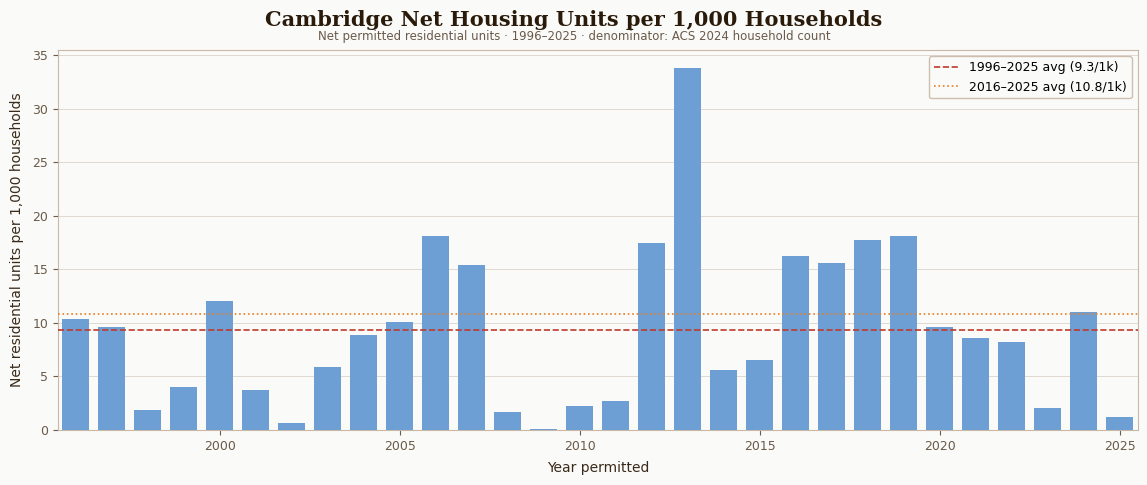

Saved → ../data/out/housing_starts_per_1k.png


In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("#fafaf8")
ax.set_facecolor("#fafaf8")
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.07, right=0.97)

ax.bar(years_full, per1k_arr, color="#6e9fd4", width=0.75, zorder=3)
ax.axhline(avg_all / DENOM, color="#c0392b", linewidth=1.2, linestyle="--",
           label=f"1996–2025 avg ({avg_all/DENOM:.1f}/1k)", zorder=4)
ax.axhline(avg_recent / DENOM, color="#e67e22", linewidth=1.2, linestyle=":",
           label=f"2016–2025 avg ({avg_recent/DENOM:.1f}/1k)", zorder=4)

ax.set_xlim(min(years_full) - 0.5, max(years_full) + 0.5)
ax.set_ylim(0)
ax.set_xlabel("Year permitted", fontsize=10, color="#3a2a1a", labelpad=6)
ax.set_ylabel("Net residential units per 1,000 households", fontsize=10, color="#3a2a1a", labelpad=6)
ax.tick_params(colors="#6a5a4a", labelsize=9)
ax.grid(axis="y", color="#e0d8d0", linewidth=0.7, zorder=0)
for spine in ax.spines.values():
    spine.set_edgecolor("#c8b8a8")
ax.legend(fontsize=9, framealpha=0.9, edgecolor="#c8b8a8", facecolor="#fafaf8")

fig.text(0.5, 0.96, "Cambridge Net Housing Units per 1,000 Households",
         ha="center", va="top", fontsize=15, fontweight="bold",
         color="#2a1a0a", fontfamily=SERIF)
fig.text(0.5, 0.92, "Net permitted residential units · 1996–2025 · denominator: ACS 2024 household count",
         ha="center", va="top", fontsize=8.5, color="#6b5a4a")

OUT_PATH = DATA_OUT / "housing_starts_per_1k.png"
plt.savefig(OUT_PATH, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print(f"Saved → {OUT_PATH}")

## Summary

**Finding:** Cambridge is severely unaffordable by every standard benchmark.

⚠️ **Interpretation:** The condo PTI (~6×) represents the most accessible ownership pathway, yet is still well above the 5× severe unaffordability threshold. The SFH PTI (~13×) places single-family ownership beyond reach for all but the highest-earning households. Supply (starts per 1k) has been declining since 2018, narrowing the path to affordability further.

---

**NYT metro estimate** (Cambridge-Newton-Framingham, MA MSA): PTI 6.5×, median home price $835,000, median HH income $128,400, avg. annual housing starts 18.9/1k. Source: *New York Times* interactive (`../data/raw/nyt_cambridge_metro_estimate.jpeg`). The metro geography is broader than Cambridge city; income and price reflect the full MSA. The higher starts figure (18.9 vs. our 10.8) likely reflects gross rather than net units and the inclusion of faster-growing suburban towns in the metro.


In [11]:
# NYT metro estimate (Cambridge-Newton-Framingham MSA) — hardcoded from screenshot
NYT_METRO_PRICE   = 835_000
NYT_METRO_INC     = 128_400
NYT_METRO_PTI     = 6.5
NYT_METRO_STARTS  = 18.9  # avg annual starts per 1k HH; likely gross, metro geography

print("=" * 62)
print("  Cambridge Housing Affordability Summary (2024 dollars)")
print("=" * 62)
print(f"  Median household income (ACS 2024, city):   ${MEDIAN_HH_INC:>10,.0f}")
print(f"  Median condo price (2022–24, 2024$):        ${MEDIAN_CONDO:>10,.0f}")
print(f"  Median SFH price   (2022–24, 2024$):        ${MEDIAN_SFH:>10,.0f}")
print(f"  Median all res.    (2022–24, 2024$):        ${MEDIAN_ALL:>10,.0f}")
print(f"  ZHVI 2024 annual avg (estimate, city):      ${ZHVI_2024_AVG:>10,.0f}")
print(f"  Price-to-income ratio — condo:               {pti_condo:>9.1f}×")
print(f"  Price-to-income ratio — SFH:                 {pti_sfh:>9.1f}×")
print(f"  Price-to-income ratio — all res.:            {pti_all:>9.1f}×")
print(f"  Price-to-income ratio — ZHVI:                {ZHVI_PTI:>9.1f}×")
print()
print(f"  Housing starts per 1,000 HH:")
print(f"                              Gross       Net")
print(f"    1996–2025 avg            {AVG_GROSS_ALL/DENOM:>5.1f}     {AVG_NET_ALL/DENOM:>5.1f}")
print(f"    2016–2025 avg            {AVG_GROSS_RECENT/DENOM:>5.1f}     {AVG_NET_RECENT/DENOM:>5.1f}")
print()
print(f"  --- NYT metro (Cambridge-Newton-Framingham MSA) ---")
print(f"  Median home price (nominal):                ${NYT_METRO_PRICE:>10,.0f}")
print(f"  Median HH income (nominal):                 ${NYT_METRO_INC:>10,.0f}")
print(f"  Price-to-income ratio:                       {NYT_METRO_PTI:>9.1f}×")
print(f"  Avg starts/1k HH (gross, metro):             {NYT_METRO_STARTS:>9.1f}")
print("=" * 62)

  Cambridge Housing Affordability Summary (2024 dollars)
  Median household income (ACS 2024, city):   $   143,108
  Median condo price (2022–24, 2024$):        $   932,626
  Median SFH price   (2022–24, 2024$):        $ 1,950,809
  Median all res.    (2022–24, 2024$):        $ 1,106,706
  ZHVI 2024 annual avg (estimate, city):      $ 1,021,329
  Price-to-income ratio — condo:                     6.5×
  Price-to-income ratio — SFH:                      13.6×
  Price-to-income ratio — all res.:                  7.7×
  Price-to-income ratio — ZHVI:                      7.1×

  Housing starts per 1,000 HH:
                              Gross       Net
    1996–2025 avg             12.9       9.3
    2016–2025 avg             18.0      10.8

  --- NYT metro (Cambridge-Newton-Framingham MSA) ---
  Median home price (nominal):                $   835,000
  Median HH income (nominal):                 $   128,400
  Price-to-income ratio:                             6.5×
  Avg starts/1k HH (gros